# Load cell zero (ADC tare) drift test

Overnight run with nothing on the load cell, no calibration loaded (`NO_CAL`).
This notebook plots the raw ADC zero over time, flags spikes, and checks how much of the drift tracks temperature.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

CSV_PATH = "lys2.csv"   # <-- change to your logger file

# Spike detection: points further than this many robust SDs (MAD-based) from a rolling median
SPIKE_WINDOW = 5      # samples (odd number)
SPIKE_THRESH = 5.0

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Load data

In [18]:
df = pd.read_csv(CSV_PATH, na_values=["NaN", "nan", ""])
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
df["status"] = df["status"].fillna("")
df["hours"] = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds() / 3600

print(f"{len(df)} records, {df['timestamp'].min()} -> {df['timestamp'].max()} "
      f"({df['hours'].iloc[-1]:.2f} h), boot sessions: {sorted(df['boot_session'].unique())}")
df.head()

76 records, 2026-10-14 16:25:07 -> 2026-10-15 10:57:01 (18.53 h), boot sessions: [1]


,boot_session,elapsed_sec,timestamp,avg_temperature_C,avg_humidity_pct,avg_raw_adc,avg_weight_g,total_tips,status,hours
0,1,6,2026-10-14 16:25:07,21.0,97.5,57332,NaN,0,BOOT_POWERON NO_CAL DHT_2of3,0.000000
1,1,906,2026-10-14 16:39:59,21.3,95.0,64796,NaN,0,NO_CAL,0.247778
2,1,1806,2026-10-14 16:54:48,21.4,96.0,57343,NaN,0,NO_CAL,0.494722
3,1,2706,2026-10-14 17:09:37,21.4,97.0,57181,NaN,0,NO_CAL,0.741667
4,1,3606,2026-10-14 17:24:26,20.9,97.7,57080,NaN,0,NO_CAL,0.988611


## Flag spikes
A rolling median + MAD filter, so a single bad reading (e.g. a stuck/garbled ADC read) doesn't distort the drift estimate. Flagged points are still plotted, just marked.

In [19]:
adc = df["avg_raw_adc"].astype(float)
roll_med = adc.rolling(SPIKE_WINDOW, center=True, min_periods=1).median()
resid = adc - roll_med
mad = (resid - resid.median()).abs().median()
robust_sd = 1.4826 * mad if mad > 0 else resid.abs().median() + 1e-9
df["spike"] = (resid.abs() / robust_sd) > SPIKE_THRESH
# Also treat the very first sample after power-on as warm-up
df["warmup"] = df["status"].str.contains("BOOT")

clean = df[~df["spike"] & ~df["warmup"]].copy()
print(f"Spikes flagged: {df['spike'].sum()}  |  warm-up samples excluded: {df['warmup'].sum()}")
df.loc[df["spike"], ["timestamp", "avg_raw_adc", "status"]]

Spikes flagged: 8  |  warm-up samples excluded: 1


,timestamp,avg_raw_adc,status
1,2026-10-14 16:39:59,64796,NO_CAL
11,2026-10-14 19:08:13,57005,NO_CAL
18,2026-10-14 20:52:01,56722,NO_CAL
19,2026-10-14 21:06:50,56757,NO_CAL
30,2026-10-14 23:49:50,56506,NO_CAL
42,2026-10-15 02:47:42,56649,NO_CAL
74,2026-10-15 10:42:12,57699,NO_CAL
75,2026-10-15 10:57:01,57835,NO_CAL


## Summary statistics (clean samples)

In [20]:
c = clean["avg_raw_adc"]
if len(clean) >= 2:
    slope, intercept = np.polyfit(clean["hours"], c, 1)
else:
    slope, intercept = np.nan, np.nan

summary = pd.Series({
    "n samples": len(clean),
    "mean ADC": c.mean(),
    "std ADC (noise)": c.std(),
    "peak-to-peak ADC": c.max() - c.min(),
    "linear drift (counts/h)": slope,
    "total drift over run (counts)": slope * (clean["hours"].max() - clean["hours"].min()),
    "temp range (°C)": clean["avg_temperature_C"].max() - clean["avg_temperature_C"].min(),
})
summary.round(2)

n samples                           67.00
mean ADC                         56819.67
std ADC (noise)                    314.36
peak-to-peak ADC                  1102.00
linear drift (counts/h)              9.46
total drift over run (counts)      165.98
temp range (°C)                      4.80
dtype: float64

## Zero drift over time, with temperature and humidity

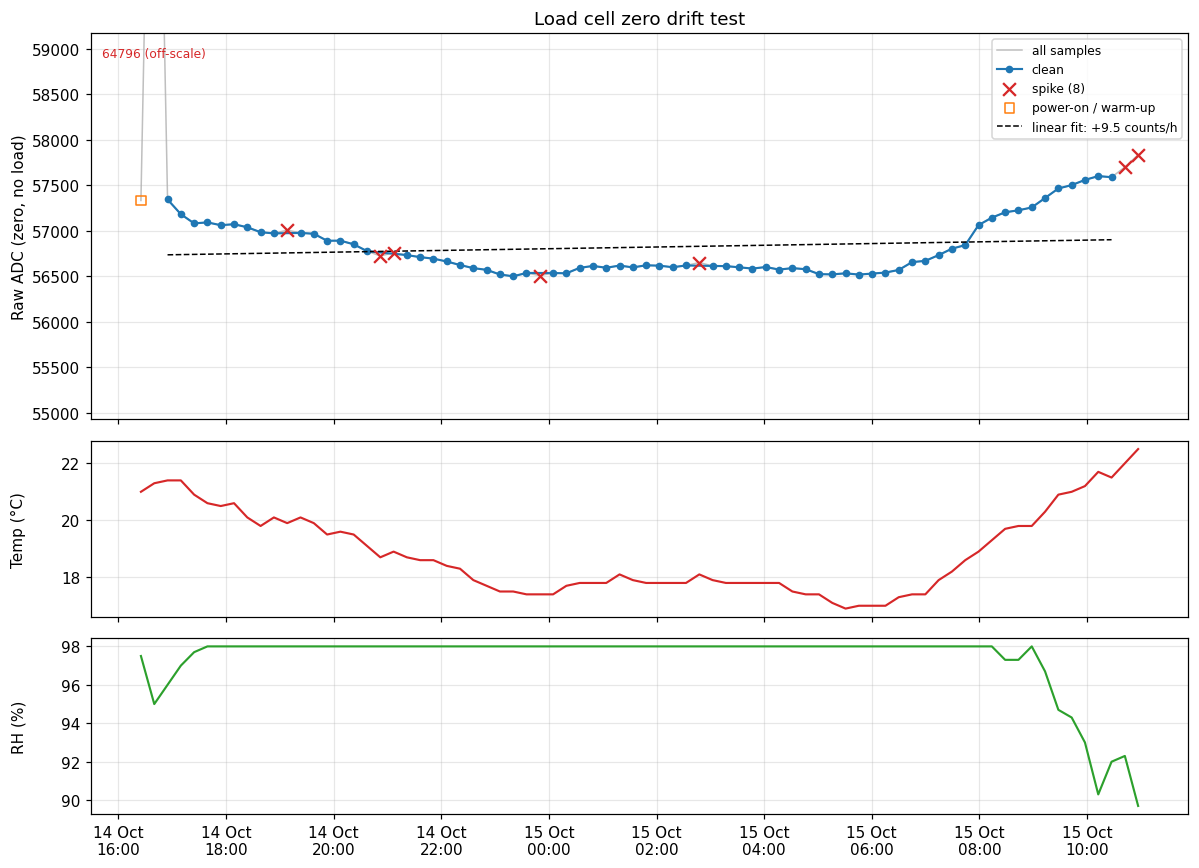

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1, 1]})

ax = axes[0]
ax.plot(df["timestamp"], df["avg_raw_adc"], color="0.75", lw=1, zorder=1, label="all samples")
ax.plot(clean["timestamp"], clean["avg_raw_adc"], "o-", color="tab:blue", ms=4, lw=1.4,
        zorder=2, label="clean")
if df["spike"].any():
    s = df[df["spike"]]
    ax.scatter(s["timestamp"], s["avg_raw_adc"], marker="x", s=70, color="tab:red", zorder=3,
               label=f"spike ({len(s)})")
if df["warmup"].any():
    w = df[df["warmup"]]
    ax.scatter(w["timestamp"], w["avg_raw_adc"], marker="s", s=40, facecolors="none",
               edgecolors="tab:orange", zorder=3, label="power-on / warm-up")
if np.isfinite(slope):
    ax.plot(clean["timestamp"], intercept + slope * clean["hours"], "--", color="k", lw=1,
            label=f"linear fit: {slope:+.1f} counts/h")

# Zoom y-axis to the clean data so spikes don't flatten the drift
if len(clean):
    pad = max(5 * c.std(), 50)
    ax.set_ylim(c.min() - pad, c.max() + pad)
    off = df[df["spike"] & ((df["avg_raw_adc"] > c.max() + pad) | (df["avg_raw_adc"] < c.min() - pad))]
    for _, r in off.iterrows():
        y = c.max() + pad * 0.9 if r["avg_raw_adc"] > c.max() else c.min() - pad * 0.9
        ax.annotate(f"{int(r['avg_raw_adc'])} (off-scale)", (r["timestamp"], y), fontsize=8,
                    color="tab:red", ha="center", va="top" if y > c.mean() else "bottom")

# Mark reboots
for t in df.loc[df["boot_session"].diff().fillna(0) != 0, "timestamp"]:
    for a in axes:
        a.axvline(t, color="tab:purple", ls=":", lw=1)

ax.set_ylabel("Raw ADC (zero, no load)")
ax.set_title("Load cell zero drift test")
ax.legend(loc="best", fontsize=8)

axes[1].plot(df["timestamp"], df["avg_temperature_C"], color="tab:red", lw=1.4)
axes[1].set_ylabel("Temp (°C)")
axes[2].plot(df["timestamp"], df["avg_humidity_pct"], color="tab:green", lw=1.4)
axes[2].set_ylabel("RH (%)")

axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
fig.align_ylabels(axes)
fig.tight_layout()
plt.show()

## Temperature sensitivity
If the zero tracks temperature, the slope here is your thermal coefficient (counts/°C) — useful for a temperature compensation term later.

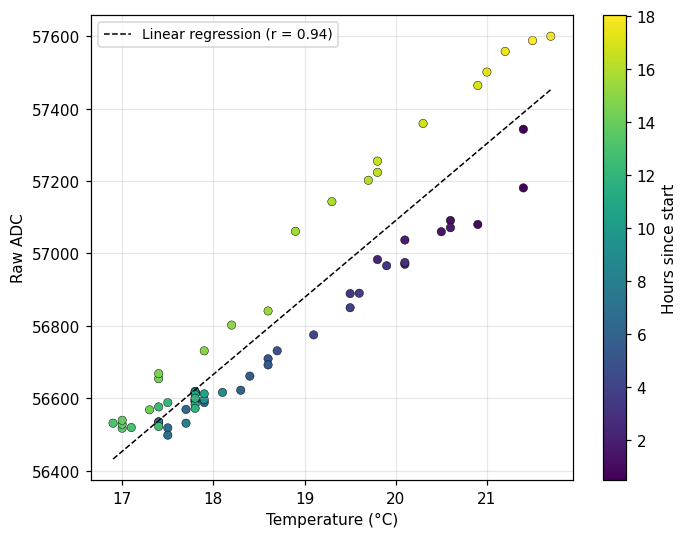

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(clean["avg_temperature_C"], clean["avg_raw_adc"], c=clean["hours"],
                cmap="viridis", s=30, edgecolor="k", lw=0.3)
fig.colorbar(sc, ax=ax, label="Hours since start")

if clean["avg_temperature_C"].nunique() > 1:
    k, b = np.polyfit(clean["avg_temperature_C"], clean["avg_raw_adc"], 1)
    r = clean[["avg_temperature_C", "avg_raw_adc"]].corr().iloc[0, 1]
    tx = np.linspace(clean["avg_temperature_C"].min(), clean["avg_temperature_C"].max(), 50)
    ax.plot(tx, k * tx + b, "k--", lw=1, label=f"Linear regression (r = {r:.2f})")
    ax.legend(fontsize=9)

ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Raw ADC")
fig.tight_layout()
plt.show()

## Detrended noise
What's left after removing the linear time drift — this is the short-term noise floor you'd see on a stable zero.

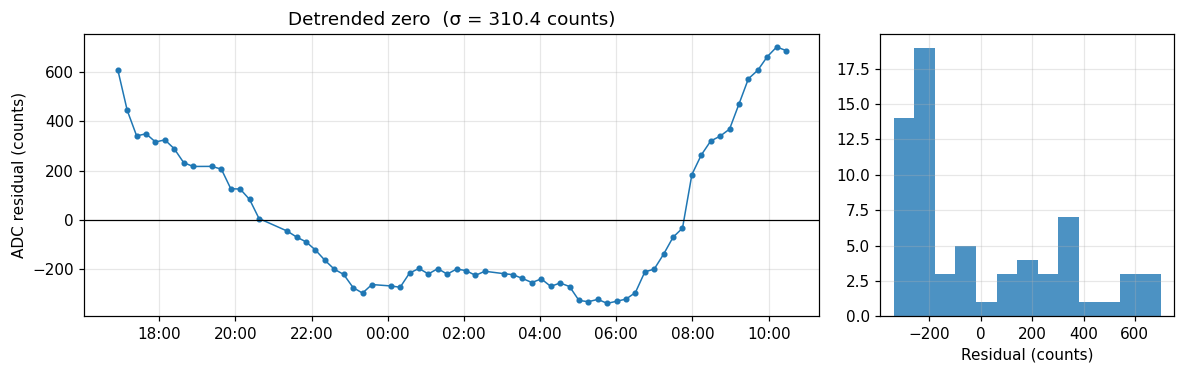

In [23]:
if np.isfinite(slope):
    clean["detrended"] = clean["avg_raw_adc"] - (intercept + slope * clean["hours"])
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [2.5, 1]})
    a1.plot(clean["timestamp"], clean["detrended"], "o-", ms=3, lw=1)
    a1.axhline(0, color="k", lw=0.8)
    a1.set_ylabel("ADC residual (counts)")
    a1.set_title(f"Detrended zero  (σ = {clean['detrended'].std():.1f} counts)")
    a1.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    a2.hist(clean["detrended"], bins=max(5, len(clean) // 5), color="tab:blue", alpha=0.8)
    a2.set_xlabel("Residual (counts)")
    fig.tight_layout()
    plt.show()

In [24]:
# ---- Daily drift of the unloaded zero ----
COUNTS_PER_G = 87.7     # calibration slope (counts/g)
ALPHA = 212.6           # zero temperature coefficient (counts/°C), overnight regression

# Clean: drop boot samples and spikes (rolling median + MAD)
adc = df["avg_raw_adc"].astype(float)
resid = adc - adc.rolling(5, center=True, min_periods=1).median()
rsd = 1.4826 * (resid - resid.median()).abs().median() or 1.0
d = df[((resid.abs() / rsd) <= 5) & ~df["status"].str.contains("BOOT")
       & df["avg_temperature_C"].notna()].copy()

# Temperature-corrected zero, referenced to the mean temperature
T0 = d["avg_temperature_C"].mean()
d["adc_tc"] = d["avg_raw_adc"] - ALPHA * (d["avg_temperature_C"] - T0)

# 1) Diurnal swing per calendar day (raw vs temperature-corrected)
daily = d.groupby(d["timestamp"].dt.date).agg(
    n=("avg_raw_adc", "size"),
    T_min=("avg_temperature_C", "min"), T_max=("avg_temperature_C", "max"),
    raw_range_counts=("avg_raw_adc", lambda x: x.max() - x.min()),
    tc_range_counts=("adc_tc", lambda x: x.max() - x.min()),
)
daily["T_range"] = daily["T_max"] - daily["T_min"]
daily["raw_range_g"] = daily["raw_range_counts"] / COUNTS_PER_G
daily["tc_range_g"] = daily["tc_range_counts"] / COUNTS_PER_G
display(daily.round(2))

# 2) Long-term drift per day: linear trend in time
#    (a) raw zero, (b) temperature-corrected zero, (c) time and temperature fitted jointly
days = d["hours"].values / 24
slope_raw = np.polyfit(days, d["avg_raw_adc"], 1)[0]
slope_tc = np.polyfit(days, d["adc_tc"], 1)[0]
X = np.column_stack([days, d["avg_temperature_C"], np.ones(len(d))])
(slope_joint, alpha_joint, _), *_ = np.linalg.lstsq(X, d["avg_raw_adc"].values, rcond=None)

span_h = d["hours"].iloc[-1] - d["hours"].iloc[0]
print(f"Record length: {span_h:.1f} h ({len(d)} clean samples)")
for name, s in [("raw zero", slope_raw),
                (f"temperature-corrected (α = {ALPHA})", slope_tc),
                (f"joint fit (α fitted = {alpha_joint:.1f})", slope_joint)]:
    print(f"  Drift, {name:38s}: {s:+8.1f} counts/day = {s / COUNTS_PER_G:+6.2f} g/day")
if span_h < 24:
    print("⚠️  Record is shorter than a day: per-day values are extrapolated.")

,n,T_min,T_max,raw_range_counts,tc_range_counts,T_range,raw_range_g,tc_range_g
timestamp,,,,,,,,
2026-10-14,25,17.4,21.4,845,204.40,4.0,9.64,2.33
2026-10-15,42,16.9,21.7,1083,282.94,4.8,12.35,3.23


Record length: 17.5 h (67 clean samples)
  Drift, raw zero                              :   +227.1 counts/day =  +2.59 g/day
  Drift, temperature-corrected (α = 212.6)     :   +469.9 counts/day =  +5.36 g/day
  Drift, joint fit (α fitted = 226.3)          :   +485.5 counts/day =  +5.54 g/day
⚠️  Record is shorter than a day: per-day values are extrapolated.
